In [1]:
import sys
from pathlib import Path
import numpy as np
import time
import warnings
from tqdm.notebook import tqdm
from dataclasses import replace
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection
import colormaps as cmaps

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda")
CFG = ROOT / "EI_cutoff" / "config" / "config_ibz.yaml"

# Ensure the root folder is in Python's search path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils.cosmetics import apply_plt_style
from utils.plotting_utils import Plotter

apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)
from utils.cosmetics import SET1_LIST

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

In [2]:
import sys
import time
import warnings
import jax 
import matplotlib.pyplot as plt
import numpy as np

from EI_refactor.EI_ness import baths as B
from EI_refactor.EI_ness import model as M

BK = "gpu"
if BK == "gpu":
    from EI_refactor.EI_ness import gpu as S
else:
    from EI_refactor.EI_ness import cpu as S
 
from EI_refactor.EI_ness import cpu as C
from EI_refactor.EI_ness import gpu as G
 
warnings.simplefilter("ignore")
print("jax", jax.__version__, jax.devices())
md = M.Model(gap=4.0, ta=1.0, tb=-1.0, v=4.1) 
g = M.sgrid(240, 128)
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
print(f"Delta_0 = {e0.d:.6f} = {e0.d * 0.1 * 11600:.6f} K, m_0 = {e0.m:.6f}, T_c = {tc * 0.1 * 11600:.6f} K")

jax 0.11.0 [CudaDevice(id=0)]
Delta_0 = 0.083537 = 96.902372 K, m_0 = -0.995752, T_c = 56.637106 K


In [3]:
md, g = M.Model(4.0, 1.0, -1.0, 2.75), M.sgrid(160, 256)
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
st = M.mf(md, g, e0.d, e0.m)
ws, gam, dip, z0 = 2*e0.d, 0.003, 0.1, 4.0
amp = 2.0 * np.pi * B.ALPHA * 3946.54 * ws**2 * 0.039  # 2 pi alpha c ws^2 fr, SiC fr = 0.039
ph = lambda t: B.Chord(t, 0.026, 0.0, 4.2e-5, 1.0, -1.0)
sp = lambda t: B.SPP(t, ws, gam, amp, dip, z0)
ok = []

In [4]:
for name, bs in (("spp", [sp(tc)]), ("chord + spp", [ph(0.5 * tc), sp(tc)])):
    pk = B.pack(bs, md, g)
    rc = C.rates(md, g, st, pk)
    rg = np.asarray(G.rates(md, G.dev(g), st, G.dev(pk)))
    err = np.max(np.abs(rg - rc)) / np.max(rc)
    ok.append(err < 1.0e-10)
    print(f"1. {name:12s} max |gpu - cpu| / max cpu = {err:.1e}")
 

1. spp          max |gpu - cpu| / max cpu = 2.5e-14
1. chord + spp  max |gpu - cpu| / max cpu = 2.5e-14


In [5]:
pk = B.pack([sp(tc)], md, g)
gg, pg = G.dev(g), G.dev(pk)
rg = G.rates(md, gg, st, pg)
db = G.check_db(rg, st.e[:, g.wi].reshape(-1), tc)
ok.append(db < 1.0e-10)
print(f"2. detailed balance residual {db:.1e}")

2. detailed balance residual 2.8e-14


In [6]:

# 3. timing: first call compiles, later calls reuse; a new state must not recompile
t0 = time.time()
jax.block_until_ready(G.rates(md, gg, M.mf(md, g, 0.9 * e0.d, e0.m), pg))
t1 = time.time()
for f in (0.8, 0.7, 0.6):
    jax.block_until_ready(G.rates(md, gg, M.mf(md, g, f * e0.d, e0.m), pg))
t2 = time.time()
tc0 = time.time()
C.rates(md, g, st, pk)
print(f"3. gpu rates: new state {t1 - t0:.3f} s, then {(t2 - t1) / 3:.3f} s per call | cpu {time.time() - tc0:.3f} s")
 

3. gpu rates: new state 0.003 s, then 0.002 s per call | cpu 0.004 s


In [7]:

# 4. equal temperatures: NESS must be the equilibrium state at that temperature
t = 0.5 * tc
pk = B.pack([ph(t), sp(t)], md, g)
s = G.solve(md, g, pk, d=e0.d, m=e0.m)
eq = M.solve_eq(md, g, t, d=1.0)
dev_d = abs(float(s.d) - eq.d) / eq.d
ok.append(bool(s.ok) and dev_d < 1.0e-6)
print(f"4. T1 = T2 = 0.5 Tc: gpu ok={s.ok} d/D0={float(s.d) / e0.d:.6f}, equilibrium {eq.d / e0.d:.6f}")



4. T1 = T2 = 0.5 Tc: gpu ok=True d/D0=0.957394, equilibrium 0.957394


In [8]:
 
# 5. two temperatures: gpu and cpu NESS agree (values from the cpu run: 0.9338, 0.8074)
for t1 in (0.55, 0.7):
    pk = B.pack([ph(0.5 * tc), sp(t1 * tc)], md, g)
    sg = G.solve(md, g, pk, d=e0.d, m=e0.m)
    sc = C.solve(md, g, pk, d=e0.d, m=e0.m)
    dd = abs(float(sg.d) - sc.d) / sc.d
    ok.append(bool(sg.ok) and bool(sc.ok) and dd < 1.0e-6)
    print(f"5. T1 = {t1} Tc: gpu d/D0={float(sg.d) / e0.d:.6f} m={float(sg.m):.6f} | "
          f"cpu d/D0={sc.d / e0.d:.6f} m={sc.m:.6f} | rel diff {dd:.1e}")
 
print("ALL OK" if all(ok) else f"FAILED: {[i + 1 for i, x in enumerate(ok) if not x]}")


5. T1 = 0.55 Tc: gpu d/D0=0.936380 m=-0.861117 | cpu d/D0=0.936380 m=-0.861117 | rel diff 6.1e-16
5. T1 = 0.7 Tc: gpu d/D0=0.830110 m=-0.861551 | cpu d/D0=0.830110 m=-0.861551 | rel diff 1.7e-15
ALL OK


0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (11 outputs left out)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

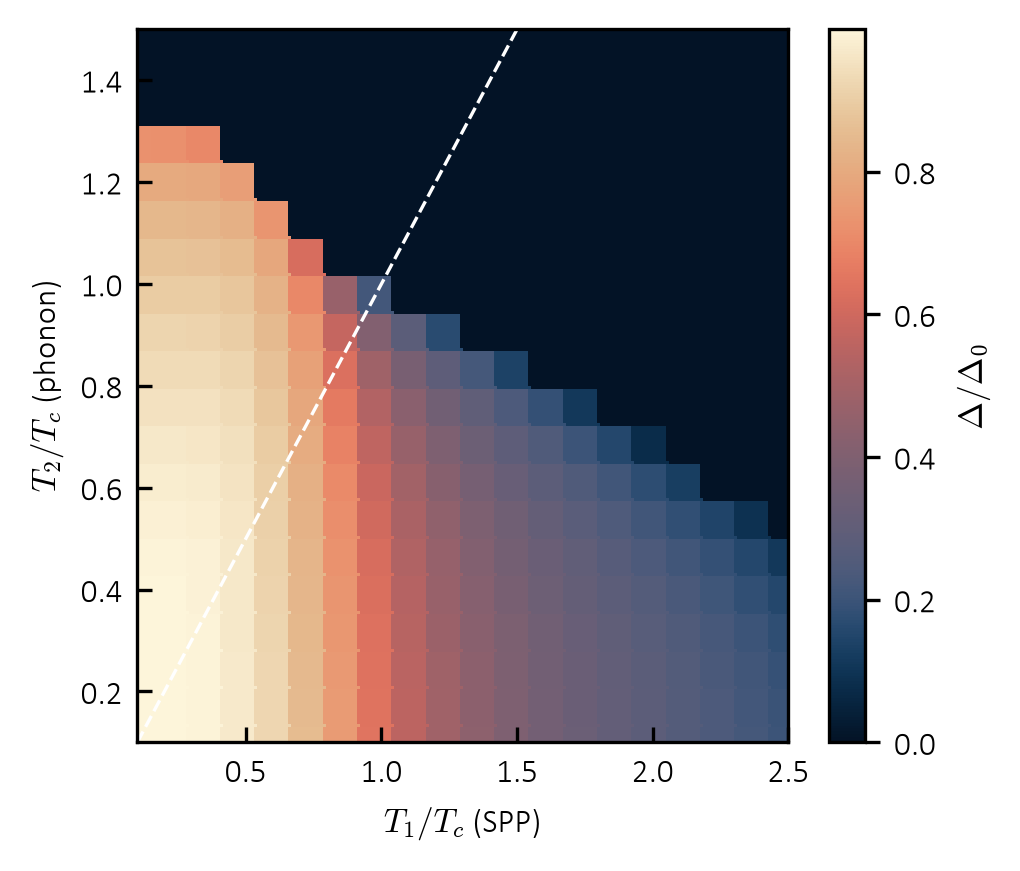

In [58]:
md = M.Model(4.0, 1.0, -1.0, 2.75)  # BCS set
g = M.sgrid(160, 256)
# SPP: SiC like plateau, amp = 2 pi alpha c ws^2 fr
ws, gam, fr, dip, z0 = 2*e0.d, 0.05, 0.039, 0.1, 40.0
amp = 2.0 * np.pi * B.ALPHA * 3946.54 * ws**2 * fr 
# phonons: sharp chord lines (gam_ph = 0: no interband phonon channel)
cs, gph, aph = 0.026, 0.05, 4.2e-5
# temperature grid in units of Tc
t1n = np.linspace(0.1, 2.5, 20)  # SPP
t2n = np.linspace(0.1, 1.5, 20)  # phonons
 
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
dd, mm, ok = (np.full((t2n.size, t1n.size), np.nan) for _ in range(3))
t0 = time.time()
for j, t2 in tqdm(enumerate(t2n)):
    d, m = None, None
    for i, t1 in tqdm(enumerate(t1n), leave=False):
        if d is None:  # start of a row: equilibrium at the colder bath
            eq = M.solve_eq(md, g, min(t1, t2) * tc, d=e0.d, m=e0.m)
            d, m = max(eq.d, 1.0e-3 * e0.d), eq.m
        pk = B.pack([B.Chord(t2 * tc, cs, gph, aph, 1.0, -1.0),
                     B.SPP(t1 * tc, ws, gam, amp, dip, z0)], md, g)
        try:
            s = S.solve(md, g, pk, d=d, m=m)
            if not s.ok:
                s = S.solve_fixed(md, g, pk, d=d, m=m)
        except ValueError as ex:
            print(f"T1={t1:.2f} T2={t2:.2f}: {ex}")
            continue
        dd[j, i], mm[j, i], ok[j, i] = float(s.d) / e0.d, float(s.m), float(s.ok)
        if s.ok and float(s.d) > 1.0e-3 * e0.d:  # continuation along the row
            d, m = float(s.d), float(s.m)
np.savez("scan_spp.npz", t1n=t1n, t2n=t2n, d=dd, m=mm, ok=ok, d0=e0.d, tc=tc,
         par=dict(md=md._asdict() if hasattr(md, "_asdict") else str(md), ws=ws, gam=gam, fr=fr,
                  dip=dip, z0=z0, cs=cs, gph=gph, aph=aph, ns=160, nf=256))
 
import matplotlib.pyplot as plt

h = 0.85
fig, ax = plt.subplots(figsize=(3.47412, h * 3.47412))
im = ax.pcolormesh(t1n, t2n, np.where(ok > 0, dd, np.nan), shading="auto", cmap=cmaps.lipari, vmin=0.0)
im.set_edgecolor("face")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta/\Delta_0$", rotation=90, labelpad=5)
lo, hi = max(t1n.min(), t2n.min()), min(t1n.max(), t2n.max())
ax.plot([lo, hi], [lo, hi], "w--", lw=0.8)  # T1 = T2
ax.set_xlabel(r"$T_1/T_c$ (SPP)")
ax.set_ylabel(r"$T_2/T_c$ (phonon)")
ax.set_xlim(t1n.min(), t1n.max())
ax.set_ylim(t2n.min(), t2n.max())
ax.tick_params(which="both", direction="in")
plt.tight_layout()
fig.savefig("scan_spp.pdf", bbox_inches="tight")